In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv('/content/weatherAUS.csv')
print(df.head())

         Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0  01-12-2008   Albury     13.4     22.9       0.6          NaN       NaN   
1  02-12-2008   Albury      7.4     25.1       0.0          NaN       NaN   
2  03-12-2008   Albury     12.9     25.7       0.0          NaN       NaN   
3  04-12-2008   Albury      9.2     28.0       0.0          NaN       NaN   
4  05-12-2008   Albury     17.5     32.3       1.0          NaN       NaN   

  WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  Humidity3pm  \
0           W           44.0          W  ...        71.0         22.0   
1         WNW           44.0        NNW  ...        44.0         25.0   
2         WSW           46.0          W  ...        38.0         30.0   
3          NE           24.0         SE  ...        45.0         16.0   
4           W           41.0        ENE  ...        82.0         33.0   

   Pressure9am  Pressure3pm  Cloud9am  Cloud3pm  Temp9am  Temp3pm  RainToday  \
0       1007.7    

In [4]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (145460, 23)

Column Names:
['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']

Data Types:
Date              object
Location          object
MinTemp          float64
MaxTemp          float64
Rainfall         float64
Evaporation      float64
Sunshine         float64
WindGustDir       object
WindGustSpeed    float64
WindDir9am        object
WindDir3pm        object
WindSpeed9am     float64
WindSpeed3pm     float64
Humidity9am      float64
Humidity3pm      float64
Pressure9am      float64
Pressure3pm      float64
Cloud9am         float64
Cloud3pm         float64
Temp9am          float64
Temp3pm          float64
RainToday         object
RainTomorrow      object
dtype: object

Missing Values:
Date                 0
Locati

In [6]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
print(df[['Date', 'Year', 'Month', 'Day']].head())

        Date  Year  Month  Day
0 2008-12-01  2008     12    1
1 2008-12-02  2008     12    2
2 2008-12-03  2008     12    3
3 2008-12-04  2008     12    4
4 2008-12-05  2008     12    5


In [7]:
df = df.drop(columns=['Sunshine'])
print("Updated Dataset Shape:")
print(df.shape)

Updated Dataset Shape:
(145460, 25)


In [8]:
df = df.dropna(subset=['MaxTemp'])
X = df.drop(columns=['MaxTemp', 'Date', 'RainTomorrow', 'Temp3pm'])
y = df['MaxTemp']
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (144199, 21)
Shape of y: (144199,)


In [9]:
np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))
train_indices = indices[:split]
test_indices = indices[split:]
X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]
y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (115359, 21)
Testing data: (28840, 21)
Training target: (115359,)
Testing target: (28840,)


In [10]:
numerical_cols = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
print("Numerical Columns:")
print(numerical_cols)
print("\nCategorical Columns:")
print(categorical_cols)
print("\nNumber of Numerical Columns:", len(numerical_cols))
print("Number of Categorical Columns:", len(categorical_cols))

Numerical Columns:
['MinTemp', 'Rainfall', 'Evaporation', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Year', 'Month', 'Day']

Categorical Columns:
['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']

Number of Numerical Columns: 16
Number of Categorical Columns: 5


In [13]:
numerical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('numerical', numerical_pipeline, numerical_cols), ('categorical', categorical_pipeline, categorical_cols)])

print("Preprocessing pipelines created successfully!")

Preprocessing pipelines created successfully!


In [14]:
X_train_final = preprocessor.fit_transform(X_train)
X_test_final = preprocessor.transform(X_test)#data leakage prevent - how
print("Training data shape:", X_train_final.shape)
print("Testing data shape:", X_test_final.shape)
print("Total features:", X_train_final.shape[1])

Training data shape: (115359, 110)
Testing data shape: (28840, 110)
Total features: 110


In [18]:
model = LinearRegression()
model.fit(X_train_final, y_train)
print("Model trained successfully!")
print("Intercept:", model.intercept_)
print("Number of weights:", len(model.coef_))

Model trained successfully!
Intercept: 23.09018985965247
Number of weights: 110


In [20]:
y_pred = model.predict(X_test_final)
print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))
print("\nFirst 10 predicted temperatures:")
print(y_pred[:10])

Predictions generated successfully!
Number of predictions: 28840

First 10 predicted temperatures:
[16.64376621 35.4911138  30.14420108 23.57005398 26.04889834 16.31169167
 21.86476455 26.31784078 30.96458453 33.6534694 ]


In [22]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("Model Evaluation Results")
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
Mean Absolute Error: 1.4781327860546294
Mean Squared Error: 3.902518943922816
Root Mean Squared Error: 1.9754794212855815
R2 Score: 0.922288464382645


In [23]:
y_train_pred = model.predict(X_train_final)
train_mae = mean_absolute_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, y_train_pred)
print("Training R2 Score:", train_r2)
print("Testing R2 Score:", r2)
print("Training MAE:", train_mae)
print("Testing MAE:", mae)

Training R2 Score: 0.9227564259930955
Testing R2 Score: 0.922288464382645
Training MAE: 1.4768645933739803
Testing MAE: 1.4781327860546294


In [25]:
performance_results = pd.DataFrame({'Model': ['Scikit-Learn Linear Regression', 'Scikit-Learn Linear Regression'], 'Dataset': ['Training', 'Testing'], 'MAE': [train_mae, mae], 'MSE': [train_mse, mse], 'RMSE': [train_rmse, rmse], 'R2 Score': [train_r2, r2]})
print(performance_results.round(4).to_string(index=False))

                         Model  Dataset    MAE    MSE   RMSE  R2 Score
Scikit-Learn Linear Regression Training 1.4769 3.9237 1.9808    0.9228
Scikit-Learn Linear Regression  Testing 1.4781 3.9025 1.9755    0.9223


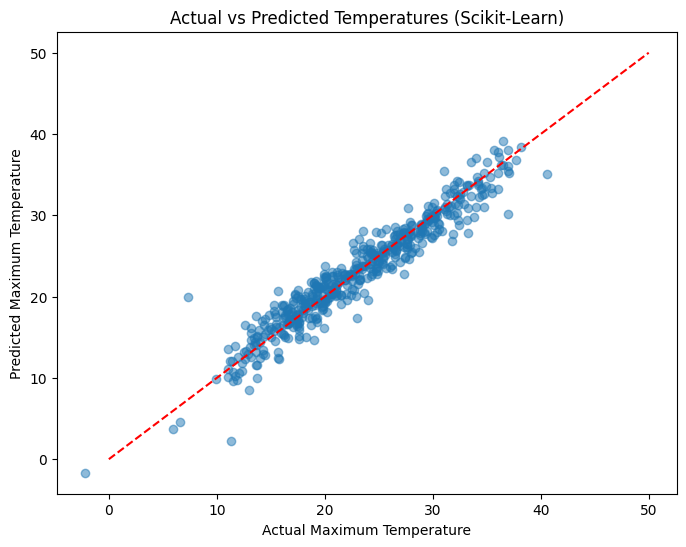

In [26]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test[:500], y_pred[:500], alpha=0.5)
plt.xlabel("Actual Maximum Temperature")
plt.ylabel("Predicted Maximum Temperature")
plt.title("Actual vs Predicted Temperatures (Scikit-Learn)")
plt.plot([0, 50], [0, 50], 'r--')
plt.show()